<a href="https://colab.research.google.com/github/keerthh129/AIML-Colab/blob/main/dl_unit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping
uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023 (1).csv
Dataset loaded successfully!
Dataset shape: (111, 60)

First five rows:


,Country,1965,1966,1967,1968,1969,1970,1971,1972,1973,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Canada,5.00,5.32,5.57,5.92,6.28,6.73,6.94,7.47,8.11,...,14.43,14.47,14.34,14.54,14.72,14.64,13.76,13.92,14.30,13.95
2,Mexico,1.06,1.12,1.14,1.24,1.36,1.45,1.53,1.69,1.82,...,8.03,7.94,8.11,8.26,8.15,8.07,7.35,7.83,8.18,8.45
3,US,51.98,54.89,56.80,60.19,63.30,65.54,66.92,70.25,73.22,...,93.59,92.69,92.62,92.97,96.37,95.68,88.64,93.44,95.42,94.28
4,Total North America,58.04,61.33,63.51,67.36,70.95,73.72,75.39,79.41,83.16,...,116.04,115.10,115.07,115.76,119.25,118.40,109.75,115.20,117.90,116.68



Column names:
['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']


In [4]:

print("Dataset columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nUploaded file name:")
print(file_name)


Dataset columns:
['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']

First 5 rows:


,Country,1965,1966,1967,1968,1969,1970,1971,1972,1973,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Canada,5.00,5.32,5.57,5.92,6.28,6.73,6.94,7.47,8.11,...,14.43,14.47,14.34,14.54,14.72,14.64,13.76,13.92,14.30,13.95
2,Mexico,1.06,1.12,1.14,1.24,1.36,1.45,1.53,1.69,1.82,...,8.03,7.94,8.11,8.26,8.15,8.07,7.35,7.83,8.18,8.45
3,US,51.98,54.89,56.80,60.19,63.30,65.54,66.92,70.25,73.22,...,93.59,92.69,92.62,92.97,96.37,95.68,88.64,93.44,95.42,94.28
4,Total North America,58.04,61.33,63.51,67.36,70.95,73.72,75.39,79.41,83.16,...,116.04,115.10,115.07,115.76,119.25,118.40,109.75,115.20,117.90,116.68



Uploaded file name:
World_Energy_By_Country_And_Region_1965_to_2023 (1).csv


In [5]:


df.columns = df.columns.astype(str).str.strip()
df = df.dropna(subset=["Country"]).copy()

india_data = df[df["Country"].astype(str).str.strip() == "India"]

if india_data.empty:
    print("India not found. Available countries:")
    print(df["Country"].tolist()[:30])
else:

    india_data = india_data.drop(columns=["Country"]).iloc[0]

    data = pd.DataFrame({
        "year": india_data.index.astype(int),
        "energy_consumption": pd.to_numeric(
            india_data.values, errors="coerce"
        )
    })

    data = data.dropna()
    data = data.sort_values("year").reset_index(drop=True)

    print("India data prepared successfully!")
    print("Number of yearly records:", len(data))
    display(data.head())
    display(data.tail())


India data prepared successfully!
Number of yearly records: 59


,year,energy_consumption
0,1965,2.23
1,1966,2.30
2,1967,2.37
3,1968,2.53
4,1969,2.81


,year,energy_consumption
54,2019,33.54
55,2020,31.78
56,2021,34.51
57,2022,36.37
58,2023,39.02


In [6]:

from sklearn.preprocessing import MinMaxScaler
import numpy as np


values = data["energy_consumption"].values.reshape(-1, 1)

split_index = int(len(values) * 0.80)

scaler = MinMaxScaler()
scaler.fit(values[:split_index])

scaled_values = scaler.transform(values)


X_train, y_train = [], []
X_test, y_test = [], []

for i in range(5, len(scaled_values)):
    X_seq = scaled_values[i-5:i]
    y_val = scaled_values[i]

    if i < split_index:
        X_train.append(X_seq)
        y_train.append(y_val)
    else:
        X_test.append(X_seq)
        y_test.append(y_val)

X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

print("Training input shape:", X_train.shape)
print("Training output shape:", y_train.shape)
print("Testing input shape:", X_test.shape)
print("Testing output shape:", y_test.shape)
print("Data preparation completed!")


Training input shape: (42, 5, 1)
Training output shape: (42, 1)
Testing input shape: (12, 5, 1)
Testing output shape: (12, 1)
Data preparation completed!


In [7]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Input(shape=(5, 1)),
    LSTM(50, activation="tanh"),
    Dense(25, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("LSTM model training completed successfully!")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,701 (45.71 KB)

 Trainable params: 11,701 (45.71 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - loss: 0.0626 - val_loss: 0.4603
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0415 - val_loss: 0.3459
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0240 - val_loss: 0.2353
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0121 - val_loss: 0.1409
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0070 - val_loss: 0.0733
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0077 - val_loss: 0.0367
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0095 - val_loss: 0.0244
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0080 - val_loss: 0.0264
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0051 - val_loss: 0.0305
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0032 - val_loss: 0.0255
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0019 - val_loss: 0.0153
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0012 - val_lo

In [8]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

predictions_scaled = model.predict(X_test)


y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

y_pred_actual = scaler.inverse_transform(
    predictions_scaled
).flatten()

mae = mean_absolute_error(y_test_actual, y_pred_actual)

rmse = np.sqrt(
    mean_squared_error(y_test_actual, y_pred_actual)
)

print("Model Evaluation Results")
print("------------------------")
print("Country: India")
print("Model: LSTM")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
Model Evaluation Results
------------------------
Country: India
Model: LSTM
MAE: 2.0578
RMSE: 2.1916


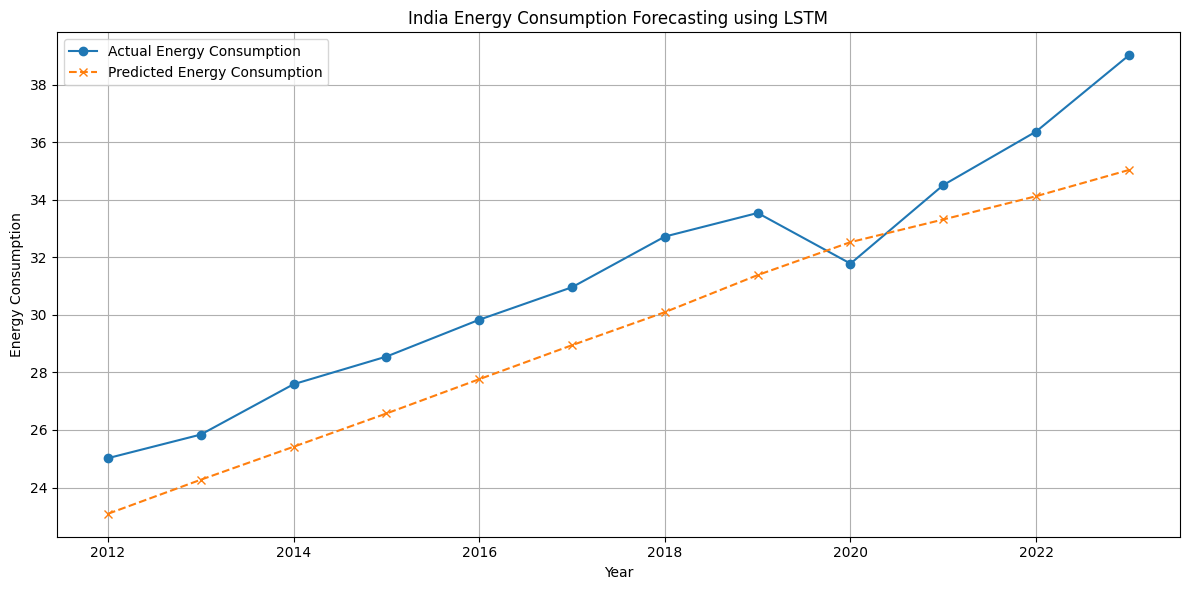

In [9]:

import matplotlib.pyplot as plt
test_years = data["year"].values[split_index:]
plt.figure(figsize=(12, 6))

plt.plot(
    test_years,
    y_test_actual,
    marker="o",
    label="Actual Energy Consumption"
)

plt.plot(
    test_years,
    y_pred_actual,
    marker="x",
    linestyle="--",
    label="Predicted Energy Consumption"
)

plt.title("India Energy Consumption Forecasting using LSTM")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [10]:
results = pd.DataFrame({
    "Year": test_years,
    "Actual Energy Consumption": y_test_actual,
    "Predicted Energy Consumption": y_pred_actual
})


results["Absolute Error"] = abs(
    results["Actual Energy Consumption"]
    - results["Predicted Energy Consumption"]
)

print("India Energy Consumption Prediction Results")
display(results.round(3))


India Energy Consumption Prediction Results


,Year,Actual Energy Consumption,Predicted Energy Consumption,Absolute Error
0,2012,25.02,23.087000,1.933
1,2013,25.84,24.271000,1.569
2,2014,27.59,25.417000,2.173
3,2015,28.55,26.573000,1.977
4,2016,29.83,27.764000,2.066
5,2017,30.96,28.945999,2.014
6,2018,32.72,30.093000,2.627
7,2019,33.54,31.382000,2.158
8,2020,31.78,32.526001,0.746
9,2021,34.51,33.313999,1.196


In [11]:

last_five_years = scaled_values[-5:]
next_input = last_five_years.reshape(1, 5, 1)
next_scaled = model.predict(next_input, verbose=0)
next_consumption = scaler.inverse_transform(
    next_scaled
)[0, 0]

last_year = int(data["year"].iloc[-1])
next_year = last_year + 1

print("Future Energy Consumption Forecast")
print("----------------------------------")
print("Country: India")
print("Last available year:", last_year)
print("Predicted year:", next_year)
print(
    f"Predicted energy consumption: {next_consumption:.3f}"
)


Future Energy Consumption Forecast
----------------------------------
Country: India
Last available year: 2023
Predicted year: 2024
Predicted energy consumption: 36.054


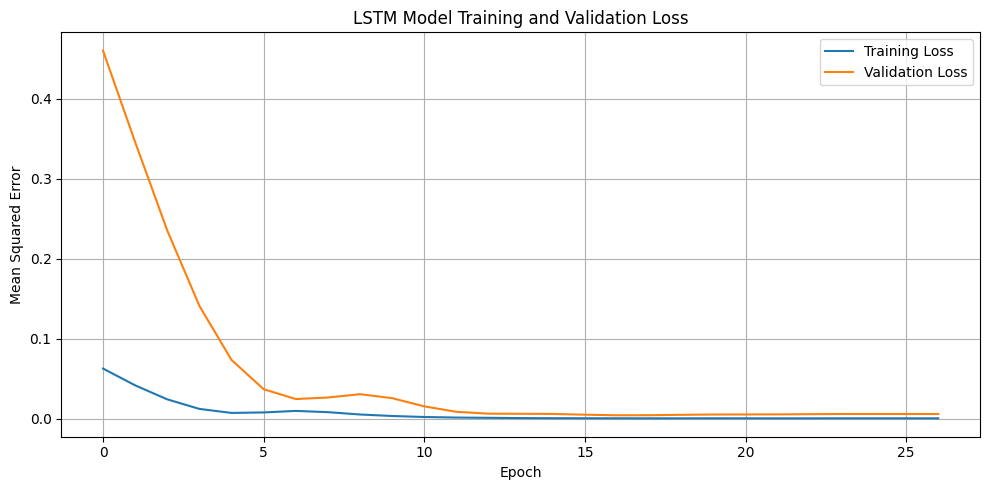

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Model Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [13]:

print("WORLD ENERGY CONSUMPTION FORECASTING")
print("=" * 45)
print("Country: India")
print("Algorithm: LSTM")
print("Sequence Length: Previous 5 Years")
print("Train-Test Split: 80%-20%")
print("-" * 45)

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")

print("-" * 45)
print("TEST DATA PREDICTIONS")
display(results.round(3))

print("-" * 45)
print(f"Predicted Energy Consumption for {next_year}: "
      f"{next_consumption:.3f}")

print("-" * 45)
print("Result: LSTM model training and forecasting completed.")


WORLD ENERGY CONSUMPTION FORECASTING
Country: India
Algorithm: LSTM
Sequence Length: Previous 5 Years
Train-Test Split: 80%-20%
---------------------------------------------
MAE  : 2.0578
RMSE : 2.1916
---------------------------------------------
TEST DATA PREDICTIONS


,Year,Actual Energy Consumption,Predicted Energy Consumption,Absolute Error
0,2012,25.02,23.087000,1.933
1,2013,25.84,24.271000,1.569
2,2014,27.59,25.417000,2.173
3,2015,28.55,26.573000,1.977
4,2016,29.83,27.764000,2.066
5,2017,30.96,28.945999,2.014
6,2018,32.72,30.093000,2.627
7,2019,33.54,31.382000,2.158
8,2020,31.78,32.526001,0.746
9,2021,34.51,33.313999,1.196


---------------------------------------------
Predicted Energy Consumption for 2024: 36.054
---------------------------------------------
Result: LSTM model training and forecasting completed.


In [14]:

actual = y_test_actual
predicted = y_pred_actual
nonzero = actual != 0

mape = np.mean(
    np.abs(
        (actual[nonzero] - predicted[nonzero])
        / actual[nonzero]
    )
) * 100

accuracy = 100 - mape

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAPE: {mape:.2f}%")
print(f"Approximate Prediction Accuracy: {accuracy:.2f}%")


MAE: 2.0578
RMSE: 2.1916
MAPE: 6.56%
Approximate Prediction Accuracy: 93.44%


In [15]:

import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

actual = y_test_actual
predicted = y_pred_actual
mae = mean_absolute_error(actual, predicted)
mse = mean_squared_error(actual, predicted)
rmse = np.sqrt(mse)
r2 = r2_score(actual, predicted)
nonzero = actual != 0

if np.any(nonzero):
    mape = np.mean(
        np.abs(
            (actual[nonzero] - predicted[nonzero])
            / actual[nonzero]
        )
    ) * 100
else:
    mape = np.nan
print("===== MODEL EVALUATION METRICS =====")
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAPE : {mape:.2f}%")
print(f"R2 Score: {r2:.4f}")


===== MODEL EVALUATION METRICS =====
MAE  : 2.0578
MSE  : 4.8033
RMSE : 2.1916
MAPE : 6.56%
R2 Score: 0.7055


In [16]:
print("Missing values:")
print(data.isnull().sum())

print("Duplicate years:", data["year"].duplicated().sum())
print("Year range:", data["year"].min(), "-", data["year"].max())
print("Total records:", len(data))

Missing values:
year                  0
energy_consumption    0
dtype: int64
Duplicate years: 0
Year range: 1965 - 2023
Total records: 59
